# Определение стоимости автомобилей

Сервис по продаже автомобилей с пробегом «Не бит, не крашен» разрабатывает приложение для привлечения новых клиентов. В нём можно быстро узнать рыночную стоимость своего автомобиля. В вашем распоряжении исторические данные: технические характеристики, комплектации и цены автомобилей. Необходимо построить модель для определения стоимости. 

Заказчику важны:

- качество предсказания;
- скорость предсказания;
- время обучения.

**Описание данных**

Данные находятся в файле /datasets/autos.csv

**Признаки**
- DateCrawled — дата скачивания анкеты из базы
- VehicleType — тип автомобильного кузова
- RegistrationYear — год регистрации автомобиля
- Gearbox — тип коробки передач
- Power — мощность (л. с.)
- Model — модель автомобиля
- Kilometer — пробег (км)
- RegistrationMonth — месяц регистрации автомобиля
- FuelType — тип топлива
- Brand — марка автомобиля
- Repaired — была машина в ремонте или нет
- DateCreated — дата создания анкеты
- NumberOfPictures — количество фотографий автомобиля
- PostalCode — почтовый индекс владельца анкеты (пользователя)
- LastSeen — дата последней активности пользователя

**Целевой признак:**
- Price — цена (евро)

## Подготовка данных

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
import re
import warnings

import sys

!"{sys.executable}" -m pip install phik
import phik

from phik import resources
from phik.binning import bin_data
from phik.report import plot_correlation_matrix

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from catboost import Pool, CatBoostRegressor, cv
from lightgbm import LGBMRegressor

from sklearn.metrics import make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
warnings.filterwarnings('ignore')

In [2]:
RANDOM_STATE = 42
CV_FOLDS = 5

In [3]:
#Загрузим данные и посмотрим информацию
df = pd.read_csv('/datasets/autos.csv')
display(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Kilometer          354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  Repaired           283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

None

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24 00:00:00,0,70435,2016-04-07 03:16:57
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24 00:00:00,0,66954,2016-04-07 01:46:50
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14 00:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17 00:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31 00:00:00,0,60437,2016-04-06 10:17:21


In [4]:
def nan (df):
    mis_val = df.isnull().sum()
    mis_val_percent = 100 * df.isnull().sum()/len(df)
    mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
    mis_val_table_ren_columns = mis_val_table.rename(
    columns = {0: 'Missing values', 1: '% of Total values'})
    return mis_val_table_ren_columns

In [5]:
nan(df)

,Missing values,% of Total values
DateCrawled,0,0.000000
Price,0,0.000000
VehicleType,37490,10.579368
RegistrationYear,0,0.000000
Gearbox,19833,5.596709
Power,0,0.000000
Model,19705,5.560588
Kilometer,0,0.000000
RegistrationMonth,0,0.000000
FuelType,32895,9.282697


In [6]:
#Функция просмотра уникальных значений
def uniq_values(data_frame):
    for column in data_frame.columns:
        print('Уникальные значения столбца', column)
        print(data_frame[column].unique())

In [7]:
uniq_values(df)

Уникальные значения столбца DateCrawled
['2016-03-24 11:52:17' '2016-03-24 10:58:45' '2016-03-14 12:52:21' ...
 '2016-03-21 09:50:58' '2016-03-14 17:48:27' '2016-03-19 18:57:12']
Уникальные значения столбца Price
[  480 18300  9800 ... 12395 18429 10985]
Уникальные значения столбца VehicleType
[nan 'coupe' 'suv' 'small' 'sedan' 'convertible' 'bus' 'wagon' 'other']
Уникальные значения столбца RegistrationYear
[1993 2011 2004 2001 2008 1995 1980 2014 1998 2005 1910 2016 2007 2009
 2002 2018 1997 1990 2017 1981 2003 1994 1991 1984 2006 1999 2012 2010
 2000 1992 2013 1996 1985 1989 2015 1982 1976 1983 1973 1111 1969 1971
 1987 1986 1988 1970 1965 1945 1925 1974 1979 1955 1978 1972 1968 1977
 1961 1960 1966 1975 1963 1964 5000 1954 1958 1967 1959 9999 1956 3200
 1000 1941 8888 1500 2200 4100 1962 1929 1957 1940 3000 2066 1949 2019
 1937 1951 1800 1953 1234 8000 5300 9000 2900 6000 5900 5911 1933 1400
 1950 4000 1948 1952 1200 8500 1932 1255 3700 3800 4800 1942 7000 1935
 1936 6500 1923 2290

In [8]:
#Отфильтруем значения и предварительно заполним явные пропуски
df_filtred = df[df['Price'] > 50]
df_filtred = df[df['Power'] > 0]
df_filtred = df[(df['RegistrationYear'] > 1990) & (df['RegistrationYear'] < 2020)]
df_filtred = df_filtred.drop('NumberOfPictures', axis = 1)
df_filtred = df_filtred.drop('LastSeen', axis = 1)
df_filtred = df_filtred.drop('DateCreated', axis = 1)
df_filtred = df_filtred.drop('PostalCode', axis = 1)
df_filtred = df_filtred.drop('DateCrawled', axis = 1)

df_filtred.loc[df['FuelType'] == 'petrol', 'FuelType'] = 'gasoline'
df_filtred.Repaired = df['Repaired'].fillna(value = 'unknown')
df_filtred.Model = df['Model'].fillna(value = 'unknown')
df_filtred.Gearbox = df['Gearbox'].fillna(value = 'unknown')
df_filtred.FuelType = df['FuelType'].fillna(value = 'other')
df_filtred.VehicleType = df['VehicleType'].fillna(value = 'other')

In [9]:
#Проверим наличие пропусков еще раз
nan(df_filtred)

,Missing values,% of Total values
Price,0,0.0
VehicleType,0,0.0
RegistrationYear,0,0.0
Gearbox,0,0.0
Power,0,0.0
Model,0,0.0
Kilometer,0,0.0
RegistrationMonth,0,0.0
FuelType,0,0.0
Brand,0,0.0


**Посмотрим корреляции признаков, предварительно проведем кодирование категорийных признаков и сохраним их в временный датасет**

In [10]:
df_filtred.columns

Index(['Price', 'VehicleType', 'RegistrationYear', 'Gearbox', 'Power', 'Model',
       'Kilometer', 'RegistrationMonth', 'FuelType', 'Brand', 'Repaired'],
      dtype='object')

In [11]:
#Функция кодировщика
def encoder(data):
    encoder = OrdinalEncoder()
    encoder.fit(data[['Gearbox', 'Brand', 'Model', 'VehicleType', 'FuelType', 'Repaired']])
    data.loc[:, ['Gearbox', 'Brand', 'Model', 'VehicleType', 'FuelType', 'Repaired']] = \
    encoder.transform(data[['Gearbox', 'Brand', 'Model', 'VehicleType', 'FuelType', 'Repaired']])
    return data

In [12]:
#Сохраним временный датасет кодированных признаков
df_encoded = df_filtred.copy()

In [13]:
df_encoded = encoder(df_encoded)

In [14]:
df_encoded.corr()[1:2]

,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired
VehicleType,-0.051716,1.0,-0.077117,-0.062829,0.005672,-0.137868,0.042675,0.038846,-0.046582,-0.049732,-0.002877


In [15]:
#Строим матрицу
df_encoded.phik_matrix()

interval columns not set, guessing: ['Price', 'VehicleType', 'RegistrationYear', 'Gearbox', 'Power', 'Model', 'Kilometer', 'RegistrationMonth', 'FuelType', 'Brand', 'Repaired']


,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired
Price,1.000000,0.286640,0.691719,0.309179,0.005803,0.233828,0.317934,0.181901,0.281684,0.315693,0.366727
VehicleType,0.286640,1.000000,0.528494,0.368052,0.006957,0.419392,0.173929,0.192788,0.421651,0.369251,0.319375
RegistrationYear,0.691719,0.528494,1.000000,0.185324,0.011737,0.199794,0.437691,0.178904,0.346100,0.206496,0.303933
Gearbox,0.309179,0.368052,0.185324,1.000000,0.006648,0.172209,0.068142,0.254907,0.311960,0.369119,0.466289
Power,0.005803,0.006957,0.011737,0.006648,1.000000,0.008024,0.000000,0.004190,0.007763,0.009215,0.012228
Model,0.233828,0.419392,0.199794,0.172209,0.008024,1.000000,0.096206,0.104243,0.191658,0.775143,0.136683
Kilometer,0.317934,0.173929,0.437691,0.068142,0.000000,0.096206,1.000000,0.060400,0.152517,0.155930,0.238844
RegistrationMonth,0.181901,0.192788,0.178904,0.254907,0.004190,0.104243,0.060400,1.000000,0.192469,0.063063,0.287147
FuelType,0.281684,0.421651,0.346100,0.311960,0.007763,0.191658,0.152517,0.192469,1.000000,0.153624,0.249818
Brand,0.315693,0.369251,0.206496,0.369119,0.009215,0.775143,0.155930,0.063063,0.153624,1.000000,0.095079


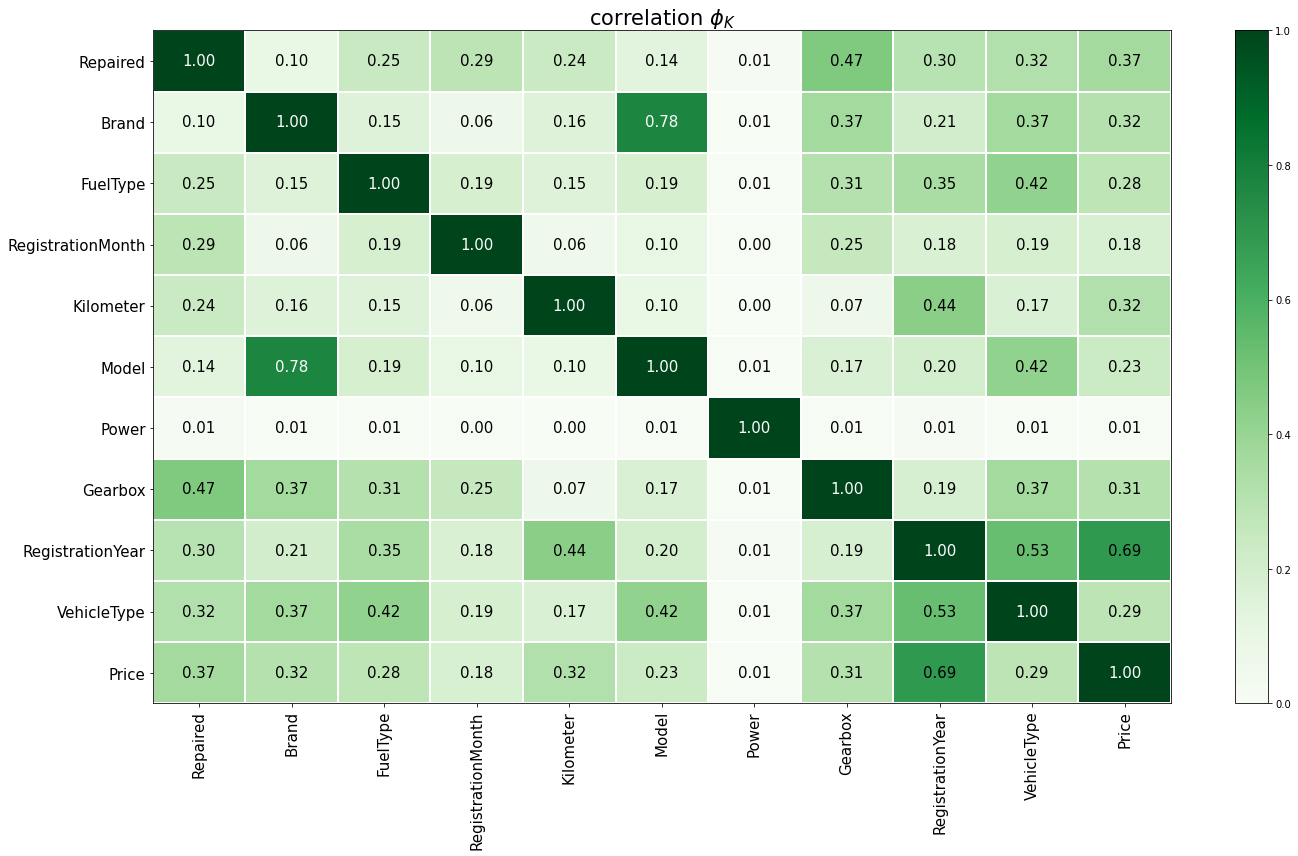

In [16]:
#Сохраним все колонки из матрицы
interval_cols = ['Price', 'VehicleType', 'RegistrationYear', 'Gearbox', 'Power', 'Model',
       'Kilometer', 'RegistrationMonth', 'FuelType', 'Brand', 'Repaired',
       'DateCreated', 'NumberOfPictures', 'PostalCode', 'LastSeen']
phik_overview = df_encoded.phik_matrix(interval_cols=interval_cols)

#Построим диаграмму
plot_correlation_matrix(phik_overview.values, 
                        x_labels=phik_overview.columns, 
                        y_labels=phik_overview.index, 
                        vmin=0, vmax=1, color_map="Greens", 
                        title=r"correlation $\phi_K$", 
                        fontsize_factor=1.5, 
                        figsize=(20, 12))
plt.tight_layout()

Из диаграммы наглядно видно, что RegistrationMonth значительно не влияет ни на один из признаков, удалим его из отфильтрованного датасета. Признак Power явно имеет некорректные значения, потребуется обработка данных, с него и начнем. По остальным признакам так же проведем подготовку данных.

In [17]:
df_filtred = df_filtred.drop('RegistrationMonth', axis = 1)

count    341789.000000
mean        111.081539
std         187.632180
min           0.000000
25%          69.000000
50%         105.000000
75%         143.000000
max       20000.000000
Name: Power, dtype: float64

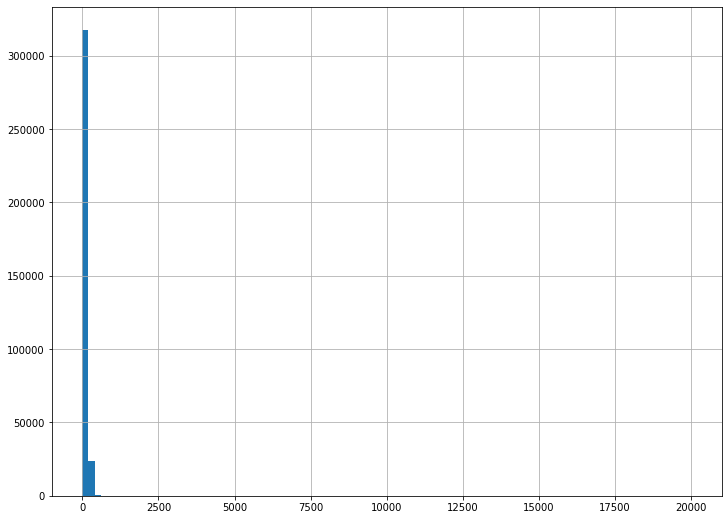

In [18]:
#Изучим признак Power
df_filtred['Power'].hist(bins=100, figsize=(12,9))
df_filtred['Power'].describe()

In [19]:
#Проведем фильтрацию значений, усечем мощность от 50 до 400
df_filtred = df_filtred[(df_filtred['Power'] < 401) & (df_filtred['Power'] > 50)]

count    288932.000000
mean       4911.057214
std        4592.457982
min           1.000000
25%        1400.000000
50%        3290.000000
75%        7000.000000
max       20000.000000
Name: Price, dtype: float64

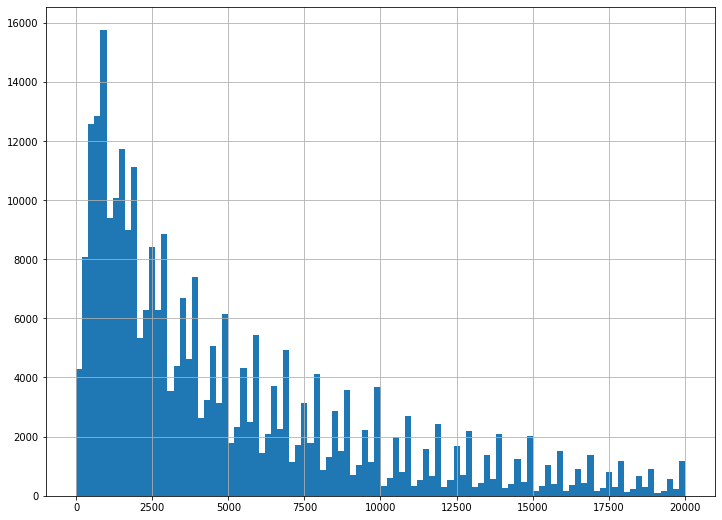

In [20]:
#Изучим значения признака Price
df_filtred = df_filtred.query('Price > 0')
df_filtred['Price'].hist(bins=100, figsize=(12,9))
df_filtred['Price'].describe()

In [21]:
df_filtred = df_filtred[(df_filtred['Price'] > 1)]

count    288320.000000
mean       2004.012007
std           5.869445
min        1991.000000
25%        2000.000000
50%        2004.000000
75%        2008.000000
max        2019.000000
Name: RegistrationYear, dtype: float64

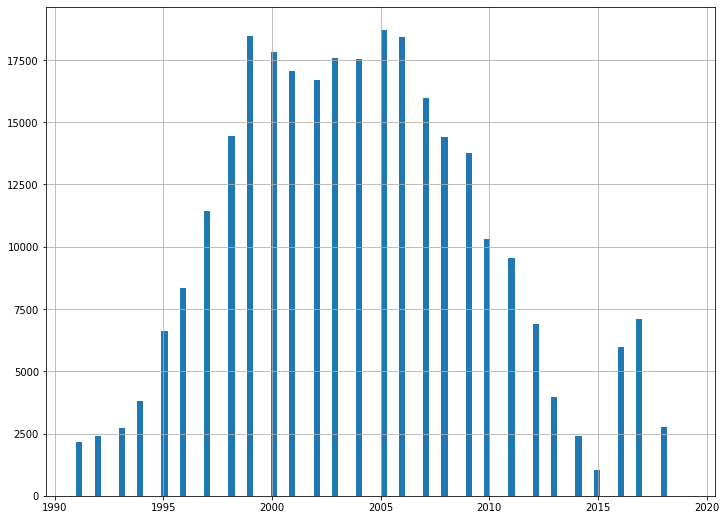

In [22]:
#Изучим значения года признака RegistrationYear
df_filtred['RegistrationYear'].hist(bins=100, figsize=(12,9))
df_filtred['RegistrationYear'].describe()

RegistrationYear аномалий не наблюдается

0

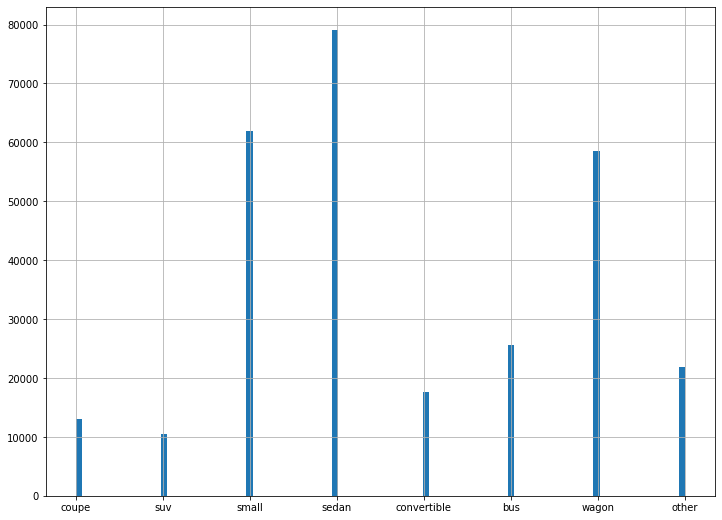

In [23]:
#Изучим значения VehicleType
df_filtred['VehicleType'].hist(bins=100, figsize=(12,9))
df_filtred['VehicleType'].describe()
df_filtred['VehicleType'].isna().sum()

VehicleType аномалий не наблюдается

0

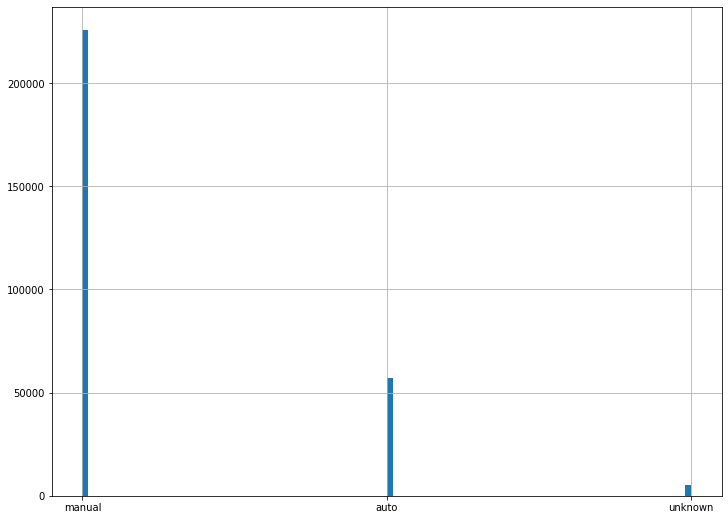

In [24]:
#Изучим значения Gearbox
df_filtred['Gearbox'].hist(bins=100, figsize=(12,9))
df_filtred['Gearbox'].describe()
df_filtred['Gearbox'].isna().sum()

Заменим значение unknown на самое распространенное manual, по видимому не все клиенты считают должным указывать тип коробки manual.

In [25]:
df_filtred.loc[df_filtred['Gearbox'] == 'unknown', 'Gearbox'] = 'manual'

0

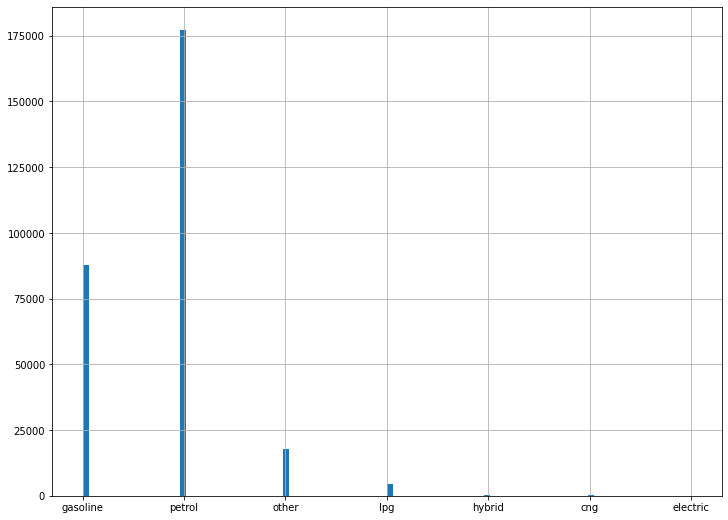

In [26]:
#Изучим значения признака FuelType
df_filtred['FuelType'].hist(bins=100, figsize=(12,9))
df_filtred['FuelType'].describe()
df_filtred['FuelType'].isna().sum()

Объеденим значения petrol и gasoline поскольку это один тип топлива, значения oter так же присвоим petrol, поскольку какое другое может быть значение если это не бензин газ или электричество. Объеденим значения lpg и cng поскольку это один тип топлива ГАЗ. Отсечем значения electric поскольку их крайне малое количество на рынке, которое не будет влиять на определение цены.

In [27]:
df_filtred.loc[df_filtred['FuelType'] == 'gasoline', 'FuelType'] = 'petrol'

In [28]:
df_filtred.loc[df_filtred['FuelType'] == 'lpg', 'FuelType'] = 'gas'
df_filtred.loc[df_filtred['FuelType'] == 'cng', 'FuelType'] = 'gas'

In [29]:
df_filtred.loc[df_filtred['FuelType'] == 'other', 'FuelType'] = 'petrol'

**Вывод по предобработке датасета**

- Изучили таблицу данных.
- Изучены корреляции признаков.
- Выявлены аномальные и пропущенные значения.
- Отсечены выбросы значений и незначительные признаки.
- Отобраны небходимые столбцы для обучения модели.
- Заполнены пропуски в столбцах и удалены некорректные значения.

## Обучение моделей

Выберем следующие регрессоры для обучения модели:

- LinearRegression
- DecisionTreeRegressor
- CatBoostRegressor
- LGBMRegressor

В качестве метрики для всех моделей будем использовать MSE и в финальной таблице переведем в RMSE. Качество моделей будем проверять на кроссвалидации.

Подготовим три типа признаков для кроссвалидации:

Неизмененные:
- Название original_features
- ohe_features - Закодированные методом OHE
- ordinal_features - Закодированные методом OE

In [30]:
#Неизмененные принаки
original_features = df_filtred.drop('Price', axis=1)

#Прямое кодирование
encoder = OrdinalEncoder()
cat_columns = ['VehicleType','FuelType','Brand','Model', 'Gearbox', 'Repaired']
cat_features = original_features[cat_columns]
cat_features = pd.DataFrame(encoder.fit_transform(cat_features),
                                columns=cat_features.columns, 
                                index=cat_features.index)
ordinal_features = original_features.copy()
for column in cat_columns:
    ordinal_features[column] = cat_features[column]

#OHE кодирование
ohe_features = pd.get_dummies(original_features, drop_first=True)

#Целевой признак
target = df_filtred['Price']

In [31]:
#Разделим данные
original_features_train, original_features_test, target_train, target_test = train_test_split(
    original_features, target, test_size=0.25, random_state=RANDOM_STATE)

ordinal_features_train = ordinal_features.loc[original_features_train.index, :]
ordinal_features_test = ordinal_features.loc[original_features_test.index, :]

ohe_features_train = ohe_features.loc[original_features_train.index, :]
ohe_features_test = ohe_features.loc[original_features_test.index, :]

In [32]:
ordinal_features.head()

,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,FuelType,Brand,Repaired
1,2.0,2011,1.0,190,224.0,125000,3.0,1.0,2.0
2,6.0,2004,0.0,163,116.0,125000,3.0,14.0,1.0
3,5.0,2001,1.0,75,115.0,150000,3.0,38.0,0.0
4,5.0,2008,1.0,69,100.0,90000,3.0,31.0,0.0
5,4.0,1995,1.0,102,11.0,150000,3.0,2.0,2.0


**Линейная регрессия**

In [33]:
%%time

regressor = LinearRegression()
print('# Train for root_mean_squared_error')
print()
cv_RMSE_LR = (cross_val_score(regressor, 
                             ohe_features_train, 
                             target_train, 
                             cv=CV_FOLDS, 
                             scoring='neg_mean_squared_error').mean() * -1) ** 0.5
print('Mean RMSE from CV of LinearRegression =', cv_RMSE_LR)

# Train for root_mean_squared_error

Mean RMSE from CV of LinearRegression = 2362.3655088485125
CPU times: user 59.1 s, sys: 1min 32s, total: 2min 31s
Wall time: 2min 32s


**Регрессия DecisionTreeRegressor**

На кодированных ОНЕ данных

In [34]:
%%time

regressor = DecisionTreeRegressor() 
max_depth_list = [x for x in range(2, 31)]
hyperparams = [{'criterion':['mse'], 
                'max_depth':max_depth_list, 
                'random_state':[RANDOM_STATE]}]

print('# Tuning hyper-parameters for root_mean_squared_error')
print()
dtr_ohe = GridSearchCV(regressor, hyperparams, scoring='neg_mean_squared_error')
dtr_ohe.fit(ohe_features_train, target_train)
print("Best parameters set found on development set:")
print()
print(dtr_ohe.best_params_)
print()
print("Grid scores on development set:")
print()
means = dtr_ohe.cv_results_['mean_test_score']
stds = dtr_ohe.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, dtr_ohe.cv_results_['params']):
    print("%0.6f for %r"% ((mean*-1)** 0.5, params))
print()

cv_RMSE_DTR_ohe = (max(means)*-1) ** 0.5

# Tuning hyper-parameters for root_mean_squared_error

Best parameters set found on development set:

{'criterion': 'mse', 'max_depth': 19, 'random_state': 42}

Grid scores on development set:

3235.987353 for {'criterion': 'mse', 'max_depth': 2, 'random_state': 42}
2923.073682 for {'criterion': 'mse', 'max_depth': 3, 'random_state': 42}
2624.285438 for {'criterion': 'mse', 'max_depth': 4, 'random_state': 42}
2403.839554 for {'criterion': 'mse', 'max_depth': 5, 'random_state': 42}
2241.968496 for {'criterion': 'mse', 'max_depth': 6, 'random_state': 42}
2125.820831 for {'criterion': 'mse', 'max_depth': 7, 'random_state': 42}
2041.510116 for {'criterion': 'mse', 'max_depth': 8, 'random_state': 42}
1979.054138 for {'criterion': 'mse', 'max_depth': 9, 'random_state': 42}
1932.675358 for {'criterion': 'mse', 'max_depth': 10, 'random_state': 42}
1892.000815 for {'criterion': 'mse', 'max_depth': 11, 'random_state': 42}
1855.222562 for {'criterion': 'mse', 'max_depth': 12, 'random_state': 42}


In [35]:
dtr_ohe_best_params = dtr_ohe.best_params_

**Регрессия DecisionTreeRegressor**

На кодированных Ordinal Encoder данных

In [36]:
%%time

regressor = DecisionTreeRegressor() 
max_depth_list = [x for x in range(2, 31)]
hyperparams = [{'criterion':['mse'], 
                'max_depth':max_depth_list, 
                'random_state':[RANDOM_STATE]}]

print('# Tuning hyper-parameters for root_mean_squared_error')
print()
dtr_ord = GridSearchCV(regressor, hyperparams, scoring='neg_mean_squared_error')
dtr_ord.fit(ordinal_features_train, target_train)
print("Best parameters set found on development set:")
print()
print(dtr_ord.best_params_)
print()
print("Grid scores on development set:")
print()
means = dtr_ord.cv_results_['mean_test_score']
stds = dtr_ord.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, dtr_ord.cv_results_['params']):
    print("%0.6f for %r"% ((mean*-1)** 0.5, params))
print()

cv_RMSE_DTR_ordinal = (max(means)*-1) ** 0.5

# Tuning hyper-parameters for root_mean_squared_error

Best parameters set found on development set:

{'criterion': 'mse', 'max_depth': 14, 'random_state': 42}

Grid scores on development set:

3235.987353 for {'criterion': 'mse', 'max_depth': 2, 'random_state': 42}
2923.073682 for {'criterion': 'mse', 'max_depth': 3, 'random_state': 42}
2625.293889 for {'criterion': 'mse', 'max_depth': 4, 'random_state': 42}
2406.443013 for {'criterion': 'mse', 'max_depth': 5, 'random_state': 42}
2255.427137 for {'criterion': 'mse', 'max_depth': 6, 'random_state': 42}
2125.027827 for {'criterion': 'mse', 'max_depth': 7, 'random_state': 42}
2040.126486 for {'criterion': 'mse', 'max_depth': 8, 'random_state': 42}
1979.341987 for {'criterion': 'mse', 'max_depth': 9, 'random_state': 42}
1922.248199 for {'criterion': 'mse', 'max_depth': 10, 'random_state': 42}
1879.243106 for {'criterion': 'mse', 'max_depth': 11, 'random_state': 42}
1840.362804 for {'criterion': 'mse', 'max_depth': 12, 'random_state': 42}


In [37]:
dtr_ord_best_params = dtr_ord.best_params_

**Регрессия CatBoostRegressor**

На кодированных Ordinal Encoder данных

In [38]:
%%time

regressor = CatBoostRegressor() 
hyperparams = [{'learning_rate':[0.1, 0.5, 0.8],
                'random_state':[RANDOM_STATE],
                'verbose':[False]}]

print('# Tuning hyper-parameters for root_mean_squared_error')
print()
cbr_ord = GridSearchCV(regressor, hyperparams, scoring='neg_mean_squared_error')
cbr_ord.fit(ordinal_features_train, target_train)
print("Best parameters set found on development set:")
print()
print(cbr_ord.best_params_)
print()
print("Grid scores on development set:")
print()
means = cbr_ord.cv_results_['mean_test_score']
stds = cbr_ord.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, cbr_ord.cv_results_['params']):
    print("%0.6f for %r"% ((mean*-1)** 0.5, params))
print()

cv_RMSE_CBR_ordinal = (max(means)*-1) ** 0.5

# Tuning hyper-parameters for root_mean_squared_error

Best parameters set found on development set:

{'learning_rate': 0.5, 'random_state': 42, 'verbose': False}

Grid scores on development set:

1566.916559 for {'learning_rate': 0.1, 'random_state': 42, 'verbose': False}
1521.687926 for {'learning_rate': 0.5, 'random_state': 42, 'verbose': False}
1543.361949 for {'learning_rate': 0.8, 'random_state': 42, 'verbose': False}

CPU times: user 7min 8s, sys: 3.34 s, total: 7min 12s
Wall time: 7min 33s


In [39]:
cbr_ord_best_params = cbr_ord.best_params_

**Регрессия CatBoostRegressor**

на оригинальных данных

In [40]:
%%time

regressor = CatBoostRegressor(learning_rate=0.5,
                              iterations = 200,
                              random_state=RANDOM_STATE, 
                              verbose=False, 
                              cat_features=['VehicleType','FuelType','Brand','Model', 'Gearbox', 'Repaired']) 
print('# Train for root_mean_squared_error')
print()
cv_RMSE_CBR_original = (cross_val_score(regressor,
                                original_features_train, 
                                target_train, 
                                cv=5, 
                                scoring='neg_mean_squared_error').mean() * -1) ** 0.5
print('Mean RMSE from CV of CatBoostRegressor =', cv_RMSE_CBR_original)

# Train for root_mean_squared_error

Mean RMSE from CV of CatBoostRegressor = 1583.2741116686022
CPU times: user 2min 53s, sys: 1.22 s, total: 2min 55s
Wall time: 2min 58s


**Регрессия LGBMRegressor**

In [41]:
%%time

regressor = LGBMRegressor() 
hyperparams = [{'num_leaves':[31, 100, 200], 
                'learning_rate':[0.1],
                'random_state':[RANDOM_STATE]}]

print('# Tuning hyper-parameters for root_mean_squared_error')
print()
lgb_ord = GridSearchCV(regressor, hyperparams, scoring='neg_mean_squared_error')
lgb_ord.fit(ordinal_features_train, target_train)
print("Best parameters set found on development set:")
print()
print(lgb_ord.best_params_)
print()
print("Grid scores on development set:")
print()
means = lgb_ord.cv_results_['mean_test_score']
stds = lgb_ord.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, lgb_ord.cv_results_['params']):
    print("%0.6f for %r"% ((mean*-1)** 0.5, params))
print()

cv_RMSE_LGBMR = (max(means)*-1) ** 0.5

# Tuning hyper-parameters for root_mean_squared_error

Best parameters set found on development set:

{'learning_rate': 0.1, 'num_leaves': 100, 'random_state': 42}

Grid scores on development set:

1565.135483 for {'learning_rate': 0.1, 'num_leaves': 100, 'random_state': 42}

CPU times: user 1h 48min 42s, sys: 1min 30s, total: 1h 50min 12s
Wall time: 1h 50min 44s


In [42]:
lgb_ord_best_params = lgb_ord.best_params_

**Вывод:**

Были изучены 4 регрессионных модели. Зафиксированы лучшие гиперпараметры и время их выполнения.

## Анализ моделей

**Линейная регрессия**

In [43]:
%%time

model = LinearRegression()
model.fit(ohe_features_train, target_train)

CPU times: user 13.7 s, sys: 19.1 s, total: 32.8 s
Wall time: 32.8 s


LinearRegression()

In [44]:
%%time

target_predict_lr = model.predict(ohe_features_test)

CPU times: user 104 ms, sys: 123 ms, total: 227 ms
Wall time: 203 ms


In [45]:
final_RMSE_LR = mean_squared_error(target_test, target_predict_lr) ** 0.5

**Регрессия DecisionTreeRegressor**

In [46]:
%%time

best_dtr_ohe_model = DecisionTreeRegressor(**dtr_ohe_best_params) 
best_dtr_ohe_model.fit(ohe_features_train, target_train)

CPU times: user 6.54 s, sys: 211 ms, total: 6.75 s
Wall time: 6.79 s


DecisionTreeRegressor(max_depth=19, random_state=42)

In [47]:
%%time

target_predict_dtr_ohe = best_dtr_ohe_model.predict(ohe_features_test)

CPU times: user 95.7 ms, sys: 70.3 ms, total: 166 ms
Wall time: 174 ms


In [48]:
final_RMSE_DTR_ohe = mean_squared_error(target_test, target_predict_dtr_ohe) ** 0.5

In [49]:
%%time

best_dtr_ord_model = DecisionTreeRegressor(**dtr_ord_best_params) 
best_dtr_ord_model.fit(ordinal_features_train, target_train)

CPU times: user 563 ms, sys: 4.28 ms, total: 567 ms
Wall time: 575 ms


DecisionTreeRegressor(max_depth=14, random_state=42)

In [50]:
%%time

target_predict_dtr_ord = best_dtr_ord_model.predict(ordinal_features_test)

CPU times: user 21.4 ms, sys: 56 µs, total: 21.4 ms
Wall time: 23.2 ms


In [51]:
final_RMSE_DTR_ordinal = mean_squared_error(target_test, target_predict_dtr_ord) ** 0.5

**Регрессия CatBoostRegressor**

In [52]:
%%time

best_cbr_ord_model = CatBoostRegressor(**cbr_ord_best_params) 
best_cbr_ord_model.fit(ordinal_features_train, target_train)

CPU times: user 32.5 s, sys: 207 ms, total: 32.7 s
Wall time: 34.1 s


In [53]:

%%time

target_predict_cbr_ord = best_cbr_ord_model.predict(ordinal_features_test)

CPU times: user 94.9 ms, sys: 0 ns, total: 94.9 ms
Wall time: 103 ms


In [54]:
final_RMSE_CBR_ordinal = mean_squared_error(target_test, target_predict_cbr_ord) ** 0.5

In [55]:
%%time

best_cbr_original_model = CatBoostRegressor(learning_rate=0.5, 
                          iterations = 200, 
                          random_state=RANDOM_STATE, 
                          verbose=False,
                          cat_features=['VehicleType','FuelType','Brand','Model', 'Gearbox', 'Repaired']) 
best_cbr_original_model.fit(original_features_train, target_train)

CPU times: user 45.7 s, sys: 270 ms, total: 46 s
Wall time: 47.1 s


In [56]:
%%time

target_predict_cbr_original = best_cbr_original_model.predict(original_features_test)

CPU times: user 206 ms, sys: 207 µs, total: 207 ms
Wall time: 206 ms


In [57]:
final_RMSE_CBR_original = mean_squared_error(target_test, target_predict_cbr_original) ** 0.5

**Регрессия LGBMRegressor**

In [59]:
#%%capture time_lgb

%%time

best_lgb_ord_model = LGBMRegressor(**lgb_ord_best_params)
best_lgb_ord_model.fit(ordinal_features_train, target_train)

CPU times: user 0 ns, sys: 5 µs, total: 5 µs
Wall time: 8.34 µs


LGBMRegressor(num_leaves=100, random_state=42)

In [61]:
%%time

target_predict_lgb = best_lgb_ord_model.predict(ordinal_features_test)

CPU times: user 752 ms, sys: 0 ns, total: 752 ms
Wall time: 715 ms


In [62]:
final_RMSE_LGBMR = mean_squared_error(target_test, target_predict_lgb) ** 0.5

**Сравнение моделей**

In [64]:
index = ['LinearRegression',
         'DecisionTreeRegressor on OHE features',
         'DecisionTreeRegressor on OE features',
         'CatBoostRegressor on OE features',
         'LGBMRegressor']
data = {'RMSE на CV, евро':[cv_RMSE_LR,
                            cv_RMSE_DTR_ohe,
                            cv_RMSE_DTR_ordinal,
                            cv_RMSE_CBR_ordinal,
                            cv_RMSE_LGBMR],
        'Время обучения на CV, сек':[108,
                                     618,
                                     66,
                                     406,
                                     6612],
        'RMSE модели на тестовой выборке, евро':[final_RMSE_LR,
                                                final_RMSE_DTR_ohe,
                                                final_RMSE_DTR_ordinal,
                                                final_RMSE_CBR_ordinal,
                                                final_RMSE_LGBMR],
        'Время обучения модели, сек':[32.8,
                                      6.75,
                                      0.567,
                                      32,
                                      0.005],
        'Время предсказания модели, сек':[0.227,
                                          0.166,
                                          0.021,
                                          0.095,
                                          0.752]}

scores_data = pd.DataFrame(data=data, index=index)
scores_data['Рейтинг RMSE'] = (scores_data['RMSE на CV, евро'].min() /
                              scores_data['RMSE на CV, евро'])
scores_data['Рейтинг времени обучения'] = (scores_data['Время обучения модели, сек'].min() / 
                              scores_data['Время обучения модели, сек'])
scores_data['Рейтинг времени предсказания'] = (scores_data['Время предсказания модели, сек'].min() / 
                              scores_data['Время предсказания модели, сек'])
scores_data['Итоговый рейтинг'] = (scores_data['Рейтинг RMSE'] +
                                   scores_data['Рейтинг времени обучения'] +
                                   scores_data['Рейтинг времени предсказания'])
scores_data

,"RMSE на CV, евро","Время обучения на CV, сек","RMSE модели на тестовой выборке, евро","Время обучения модели, сек","Время предсказания модели, сек",Рейтинг RMSE,Рейтинг времени обучения,Рейтинг времени предсказания,Итоговый рейтинг
LinearRegression,2362.365509,108,2360.146898,32.800,0.227,0.644137,0.000152,0.092511,0.736801
DecisionTreeRegressor on OHE features,1772.179415,618,1749.577729,6.750,0.166,0.858653,0.000741,0.126506,0.985900
DecisionTreeRegressor on OE features,1811.620644,66,1774.841390,0.567,0.021,0.839959,0.008818,1.000000,1.848778
CatBoostRegressor on OE features,1521.687926,406,1515.631493,32.000,0.095,1.000000,0.000156,0.221053,1.221209
LGBMRegressor,1565.135483,6612,1564.587043,0.005,0.752,0.972240,1.000000,0.027926,2.000166


**Выводы**

В рамках исследования проведено построение моделей машинного обучения с целью предсказания на основе технических характеристик цены автомобилей.

Проведена обработка исторических данных:

- Изучили таблицу данных.
- Изучены корреляции признаков.
- Выявлены аномальные и пропущенные значения.
- Отсечены выбросы значений и незначительные признаки.
- Отобраны небходимые столбцы для обучения модели.
- Заполнены пропуски в столбцах и удалены некорректные значения.

**Проведено обучение 4 различных типов моделей:**

линейная регрессия LinearRegression	
Регресия дерева решений DecisionTreeRegressor
градиентный бустинг CatBoost
градиентный бустинг LightGBM

**По результатам анализа моделей:**

Лучшей моделью по трем параметрам качество, скорость обучения и скорость предсказания можно считать LGBMRegressor. Сочетания скорости и точности на подготовленных данных выводит эту модель в лидеры рейтинга. Лучшая RMSE у модели CatBoostRegressor, но по рейтингу она на третьем месте, на втором DecisionTreeRegressor.

----

## Чек-лист проверки

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Выполнена загрузка и подготовка данных
- [ ]  Выполнено обучение моделей
- [ ]  Есть анализ скорости работы и качества моделей